## Initial Spinup Analysis: 
Comparison of model output to forcing to ensure everything is working as expected.

Notes on Julian vs Gregorian dates:
The model runs on a Julian calendar, meaning that any year divisible by 4 is a leap year. In contrast, the Gregorian calendar is similar but skips certain leap years (divisible by 100 but not 400). The most relevant date is 1900 for spinup, which is a leap year in the Julian calendar but not in the Gregorian calendar. When comparing to forcing, I need to keep this in mind.

Plotting and resampling all depend on normal datetime indicies, so I am going to convert the Julian dates to Gregorian. The land_daily data is most problematic since it typically includes 1900. I will simply switch out the calendar for the output by creating a new index that starts at the same time but uses the Gregorian calendar.

In this version I am looking at spinup completed by Enrico for MIP. It appears this spinup uses GSWP3 data.

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import os

In [4]:
# Run configuration
site = 'snb'  #Use the Snotel name
path_env = 'alpine' # 'desktop' or 'alpine'

In [6]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    forcing_path = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
    forcing_path = r'/projects/ccox1@xsede.org/lm4px_modelling/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

Load forcing:

In [7]:
spinup_forcing = xr.open_dataset(os.path.join(forcing_path, site, f'{site}_gswp3c_forcing.nc'))

In [8]:
spinup_forcing

<xarray.Dataset>
Dimensions:           (time: 262968, latitude: 1, longitude: 1)
Coordinates:
  * time              (time) datetime64[ns] 1980-10-01T06:59:56 ... 2010-10-0...
  * latitude          (latitude) float64 37.91
  * longitude         (longitude) float64 -107.7
Data variables:
    LWdown            (time, latitude, longitude) float32 ...
    Psurf             (time, latitude, longitude) float32 ...
    Qair              (time, latitude, longitude) float32 ...
    Rainf             (time, latitude, longitude) float32 ...
    Snowf             (time, latitude, longitude) float32 ...
    SWdown            (time, latitude, longitude) float32 ...
    Tair              (time, latitude, longitude) float32 ...
    Wind              (time, latitude, longitude) float32 ...
    reference_height  (latitude, longitude) float64 ...
    canopy_height     (latitude, longitude) float64 ...

In [39]:
def get_spinup_forcing(forcing_ds: xr.Dataset, var_name: str) -> pd.Series:
    '''
    Extract a given variable (at a daily timestep) from the forcing dataset and loop it for the 100 year spinup period.
    Return a pandas Series with the looped data.
    '''
    # If 'precip' get sum of 'Rainf' and 'Snowf'
    if var_name == 'precip':
        forcing_ds = forcing_ds.assign(precip=forcing_ds['Rainf'] + forcing_ds['Snowf'])
    
    # Extract the variable data
    var_df = forcing_ds[var_name].isel(latitude=0, longitude=0).to_dataframe()
    data = var_df[var_name] # Extract the variable column
    data.index = data.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900

    # Resample to daily frequency
    data_daily = data.resample('D').mean()

    # Loop the data for 100 years
    model_start_year = data_daily.index[-1].year - 100
    model_start = data_daily.index[0].replace(year=model_start_year)
    model_end = data_daily.index[-1] + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
    model_index = pd.date_range(start=model_start, end=model_end, freq='D')

    # Loop the data to fill the 100-year period, using 11 groups instead of 10 to ensure full coverage
    looped = pd.concat([data_daily] * 11, ignore_index=True)

    # Ensure the looped data matches the model index length
    looped_values = looped[:len(model_index)].values

    # Shift index by 12 hours to match model output
    model_index = model_index + pd.Timedelta(hours=12)

    output = pd.Series(looped_values, index=model_index)
    output.name = var_name

    return output
    


Load diagnostics

In [9]:
output_folder = os.path.join(output_path,f'{site}/{site}_spinup_enrico/history/')

It appears there is no land daily output. Furthermore, there are a couple of options for land_monthly.

In [9]:
# Find the land daily file name in folder and open
land_daily=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_daily.nc"):
        land_daily = xr.open_dataset(output_folder + filename)
if not land_daily:
    print('Error: no land daily found')

In [10]:
# Create a dataframe whose index is the name of the variable and the columns are: dimensions, long_name, units
daily_vars_df = pd.DataFrame({
    'dimensions': [land_daily[var].dims for var in land_daily.data_vars],
    'long_name': [land_daily[var].attrs.get('long_name', '') for var in land_daily.data_vars],
    'units': [land_daily[var].attrs.get('units', '') for var in land_daily.data_vars]
}, index=land_daily.data_vars)

In [13]:
land_daily

<xarray.Dataset> Size: 13MB
Dimensions:                  (grid_index: 1, time: 36525, nv: 2, lon: 1,
                              lonb: 2, lat: 1, latb: 2, zfull_soil: 20,
                              zhalf_soil: 21, band: 2)
Coordinates:
  * grid_index               (grid_index) float64 8B 0.0
  * time                     (time) object 292kB 1890-10-01 12:00:00 ... 1990...
  * nv                       (nv) float64 16B 1.0 2.0
  * lon                      (lon) float64 8B -106.4
  * lonb                     (lonb) float64 16B -106.9 -105.9
  * lat                      (lat) float64 8B 35.92
  * latb                     (latb) float64 16B 35.42 36.42
  * zfull_soil               (zfull_soil) float64 160B 0.01 0.04 ... 6.75 8.75
  * zhalf_soil               (zhalf_soil) float64 168B 0.0 0.02 ... 7.5 10.0
  * band                     (band) float64 16B 1.0 2.0
    geolon_t                 (grid_index) float64 8B ...
    geolat_t                 (grid_index) float64 8B ...
Data variables: (12/56)
    fco2                     (time, grid_index) float32 146kB ...
    t_ref                    (time, grid_index) float32 146kB ...
    co2_mol_flux             (time, grid_index) float32 146kB ...
    co2_mol_flux1            (time, grid_index) float32 146kB ...
    btot                     (time, grid_index) float32 146kB ...
    Ctot                     (time, grid_index) float32 146kB ...
    ...                       ...
    drydep_md                (time, grid_index) float32 146kB ...
    drydep_om                (time, grid_index) float32 146kB ...
    average_T1               (time) datetime64[ns] 292kB ...
    average_T2               (time) datetime64[ns] 292kB ...
    average_DT               (time) timedelta64[ns] 292kB ...
    time_bnds                (time, nv) object 584kB ...
Attributes:
    filename:          land_daily.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

In [ ]:
# Find the land month file name in folder and open
land_month=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_month.nc"):
        land_month = xr.open_dataset(output_folder + filename)
if not land_month:
    print('Error: no land daily found')

In [ ]:
# Create a dataframe whose index is the name of the variable and the columns are: dimensions, long_name, units
land_vars_df = pd.DataFrame({
    'dimensions': [land_month[var].dims for var in land_month.data_vars],
    'long_name': [land_month[var].attrs.get('long_name', '') for var in land_month.data_vars],
    'units': [land_month[var].attrs.get('units', '') for var in land_month.data_vars]
}, index=land_month.data_vars)

#### Calendar conversion:
Create a new calendar index that is gregorian starting at the same time as the output.

In [36]:
# Get the first time coordinate from the daily dataset
model_start_str = land_daily['time'].to_index()[0].strftime('%Y-%m-%d 12:00')
model_end_str = land_daily['time'].to_index()[-1].strftime('%Y-%m-%d 12:00')
model_start = pd.Timestamp(model_start_str)
model_end = pd.Timestamp(model_end_str) + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
output_index_gregorian = pd.date_range(start=model_start, end=model_end, freq='D')

### Analysis: Temperature
In the daily output, it appears that air temperature and shortwave radiation are the only variables that are directly comparible to the forcing data. Even so, t_ref is 2m air temperature, while the forcing is set to 10m. The shortwave radiation is also partitioned by the model into direct and diffuse components, while the forcing is total shortwave radiation.

Even so, I can make a number of comparisons to see if there is consistency.

In [37]:
model_surface_data = land_daily[['t_ref', 'snow_frac', 'snow_depth', 'Tgrnd']].isel(grid_index=0).to_dataframe()
model_surface_data.index = output_index_gregorian
model_surface_data = model_surface_data[['t_ref', 'snow_frac', 'snow_depth', 'Tgrnd']]  #Just get the variables of interest

In [40]:
# Get the forcing Tair
Tair = get_spinup_forcing(forcing_10yr, 'Tair')

C:\Users\clmbn\AppData\Local\Temp\ipykernel_15696\594127935.py:13: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  data.index = data.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900


<Axes: >

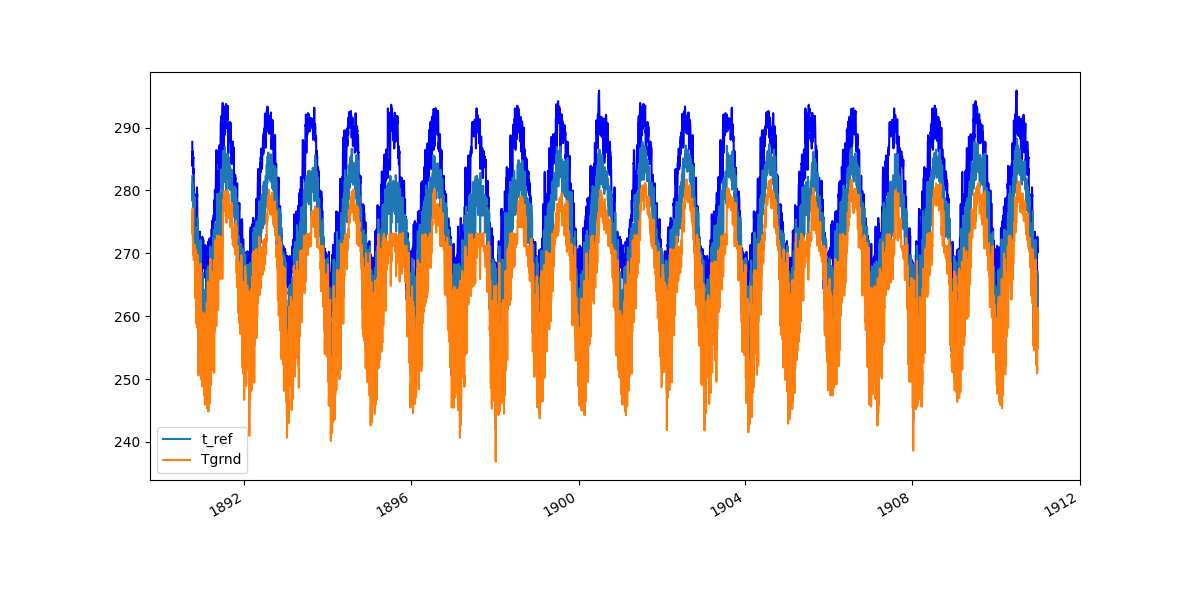

In [42]:
# Plot just the first 20 years of the Tair forcing and t_ref
fig, ax = plt.subplots(figsize=(12, 6))
Tair['1890':'1910'].plot(ax=ax, label='Tair forcing', color='blue')
model_surface_data.loc['1890':'1910',['t_ref','Tgrnd']].plot(ax=ax, label='t_ref')


In [ ]:
vegetation_data = land_month[['snow_depth','precip','Tgrnd','height','lai']].isel(grid_index=0).to_dataframe()
vegetation_data.index = vegetation_data.index.to_datetimeindex()

# Drop all extraneous columns
vegetation_data = vegetation_data[['snow_depth','precip','Tgrnd','height','lai']]

Compare precip to verify that the forcing is correct.

In [ ]:
forcing_precip = get_spinup_forcing(forcing_10yr, 'precip')
forcing_precip_month = forcing_precip.resample('MS').mean()

# Shift index forward 15 days to match the land month data
forcing_precip_month.index = forcing_precip_month.index + pd.DateOffset(days=15)

In [ ]:
# Plot precip datasets on the same plot
fig, ax = plt.subplots(figsize=(12, 6))
forcing_precip_month.plot(ax=ax, label='Forcing Precipitation', color='blue')
vegetation_data['precip'].plot(ax=ax, label='Vegetation Precipitation', color='orange')

The two datasets should basically be the same, although the land_month data might be averaged differently with a julian calendar. At least they are quite similar.

In [ ]:
vegetation_data.plot(subplots=True, figsize=(10, 6), title='Vegetation Data for ' + snotel_site)

- Vegetation growth is bizaar for the first 50 years or so, could this be due to soil properties or a model bug?

### Analysis: Soil

In [ ]:
# Function for extracting soil data
def extract_soil_data(soil_var) -> pd.DataFrame:
    soil_data = land_month[[soil_var]].isel(grid_index=0).to_dataframe()
    soil_data_df = soil_data.reset_index().pivot(index='time', columns='zfull_soil', values=soil_var)
    soil_data_df.columns.name = 'Depth'
    soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
    soil_data_df.columns = [f"{col:03.2f}" for col in soil_data_df.columns]
    return soil_data_df

In [ ]:
# Extract the soil data at different depths
soil_T = extract_soil_data('soil_T')
soil_liq = extract_soil_data('soil_liq')
soil_ice = extract_soil_data('soil_ice')

In [ ]:
# Get air temperature from forcing data
Tair = get_spinup_forcing(forcing_10yr, 'Tair')
Tair_month = Tair.resample('MS').mean()

In [ ]:
# Merge in ground surface temperature and air temperature
soil_T['Tgrnd'] = vegetation_data['Tgrnd']
soil_T['Tair'] = Tair_month.to_numpy()

# Change soil_T values from Kelvin to Celsius
soil_T = soil_T - 273.15

# Add snow depth to soil_T dataframe
soil_T['snow_depth'] = vegetation_data['snow_depth']

In [ ]:
soil_T[['Tair','snow_depth','Tgrnd','0.01','1.20','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Temperature at Different Depths for ' + snotel_site)

This data doesn't make sense. There is almost a meter of snow on the ground early on but the ground surface is at -20 degrees C. This is not possible, the ground surface should be at 0 degrees C if there is snow on the ground.

In [ ]:
soil_ice[['0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Ice at Different Depths for ' + snotel_site)

In [ ]:
# Add precip to soil_liq dataframe
soil_liq['precip'] = vegetation_data['precip']

In [ ]:
soil_liq[['precip','0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Liquid Water at Different Depths for ' + snotel_site)

Liquid water looks fairly normal except deeper where there appears to be permafrost for a long time.

What is the fractional snow cover?

In [ ]:
# Get the fractional snow cover from the land month data
fsc = land_month['snow_frac'].isel(grid_index=0).to_dataframe()